# HW04：降维、PCA 与 UMAP

**姓名：**黄诗妍　　**学号：**32320232203033　　**完成日期：**2026-11-03

本报告使用 Golub 白血病微阵列表达数据，完成描述性 PCA、原尺度敏感性对照、四组 UMAP 单因素对照和可选训练内交叉验证。

> 核心结论：二维图可以展示当前 72 份记录在特定分析设置下的候选结构，但不能单独证明疾病机制、真实亚型数量或新患者预测能力。

**拟合范围：**描述性 PCA/UMAP 在全部 72 行拟合，`diagnosis` 只在拟合后着色；可选预测比较只使用原始 38 个 train 样本，并把所有拟合步骤放入每个训练折。

## 0. 环境、路径与复现约定

Notebook 会从当前目录向上寻找课程仓库，因此从仓库根目录或个人提交目录启动均可。可再生坐标表与缓存写入课程规定的 `.tmp/dimension-reduction/student-results/`，不复制数据到提交目录。

In [1]:
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
import numpy as np
import pandas as pd
import scipy
from scipy.spatial import procrustes
from IPython.display import display
import sklearn
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import threadpoolctl
import umap
from umap import UMAP

def locate_repo_root():
    marker = Path("assignments/hw04/resources/data/leukemia/leukemia.csv")
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError("未找到课程仓库根目录或 HW04 数据文件。")

ROOT = locate_repo_root()
DATA_PATH = ROOT / "assignments/hw04/resources/data/leukemia/leukemia.csv"
RESULT_DIR = ROOT / ".tmp/dimension-reduction/student-results/32320232203033-黄诗妍"
RESULT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "Arial Unicode MS", "DejaVu Sans"],
    "axes.unicode_minus": False, "figure.dpi": 120,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLORS = {"ALL": "#0072B2", "AML": "#D55E00"}
MARKERS = {"ALL": "o", "AML": "^"}
versions = pd.Series({
    "Python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "umap-learn": umap.__version__,
    "matplotlib": matplotlib.__version__, "threadpoolctl": threadpoolctl.__version__,
}, name="版本")
display(versions.to_frame())
print("数据路径：", DATA_PATH)
print("可再生结果目录：", RESULT_DIR)

,版本
Python,3.12.10
numpy,2.3.5
pandas,2.3.3
scipy,1.17.1
scikit-learn,1.8.0
umap-learn,0.5.12
matplotlib,3.10.8
threadpoolctl,3.6.0


数据路径： D:\Files\Downloads\git-practice-classroom-main\assignments\hw04\resources\data\leukemia\leukemia.csv
可再生结果目录： D:\Files\Downloads\git-practice-classroom-main\.tmp\dimension-reduction\student-results\32320232203033-黄诗妍


## 数据检查

一行是一份白血病样本表达谱。`sample_id` 是教学编号，不是原始患者 ID；`original_split` 是历史划分；`diagnosis` 只用于描述或监督学习目标。其余列为探针，探针数不等于不同基因数。

In [2]:
df = pd.read_csv(DATA_PATH)
meta_cols = ["sample_id", "original_split", "diagnosis"]
X = df.drop(columns=meta_cols)
y = df["diagnosis"]
assert X.shape == (72, 7129)
assert np.isfinite(X.to_numpy()).all()
assert X.columns.is_unique
assert (X.nunique(dropna=False) > 1).all()
data_check = pd.Series({
    "样本数 n": X.shape[0], "探针数 p": X.shape[1], "p/n": X.shape[1] / X.shape[0],
    "ALL 数量": int((y == "ALL").sum()), "AML 数量": int((y == "AML").sum()),
    "非有限值": int((~np.isfinite(X.to_numpy())).sum()),
    "常量探针": int((X.nunique(dropna=False) <= 1).sum()),
    "最小值": float(X.min().min()), "最大值": float(X.max().max()),
    "负值数量": int((X.to_numpy() < 0).sum()), "零值数量": int((X.to_numpy() == 0).sum()),
})
display(data_check.to_frame("实际检查"))
display(pd.crosstab(df["original_split"], y, margins=True))

,实际检查
样本数 n,72.000000
探针数 p,7129.000000
p/n,99.013889
ALL 数量,47.000000
AML 数量,25.000000
非有限值,0.000000
常量探针,0.000000
最小值,-28400.000000
最大值,71369.000000
负值数量,147174.000000


diagnosis,ALL,AML,All
original_split,,,
test,20,14,34
train,27,11,38
All,47,25,72


数据含负值，且不是 RNA-seq 原始计数，因此不直接取 `log` 或 `log1p`。来源材料缺少患者重复映射、中心和批次字段，所以不能核验患者层面的独立性，也不能宣称排除了批次效应。

## 任务 1：降维目的与拟合范围

| 目标 | 需要的输出 | 如何判断有用 |
|---|---|---|
| 可视化 | 2D/3D 坐标、样本编号、拟合后标签着色 | 可读性、参数/种子稳定性、解释边界 |
| 去噪 | 去掉不稳定方向后的表示 | 重复测量、重采样或独立数据上的稳定性，以及下游任务是否改善 |
| 压缩特征 | 较少的新坐标、累计解释率或重建误差 | 维数、解释率/误差与计算成本的权衡 |
| 发现样本结构 | 候选邻域、梯度、分组或离群点 | 对预处理、参数和重采样是否稳定，并用外部信息验证 |
| 后续模型输入 | 能一致转换新样本的低维特征 | 完整 Pipeline 的无泄露交叉验证与独立测试 |

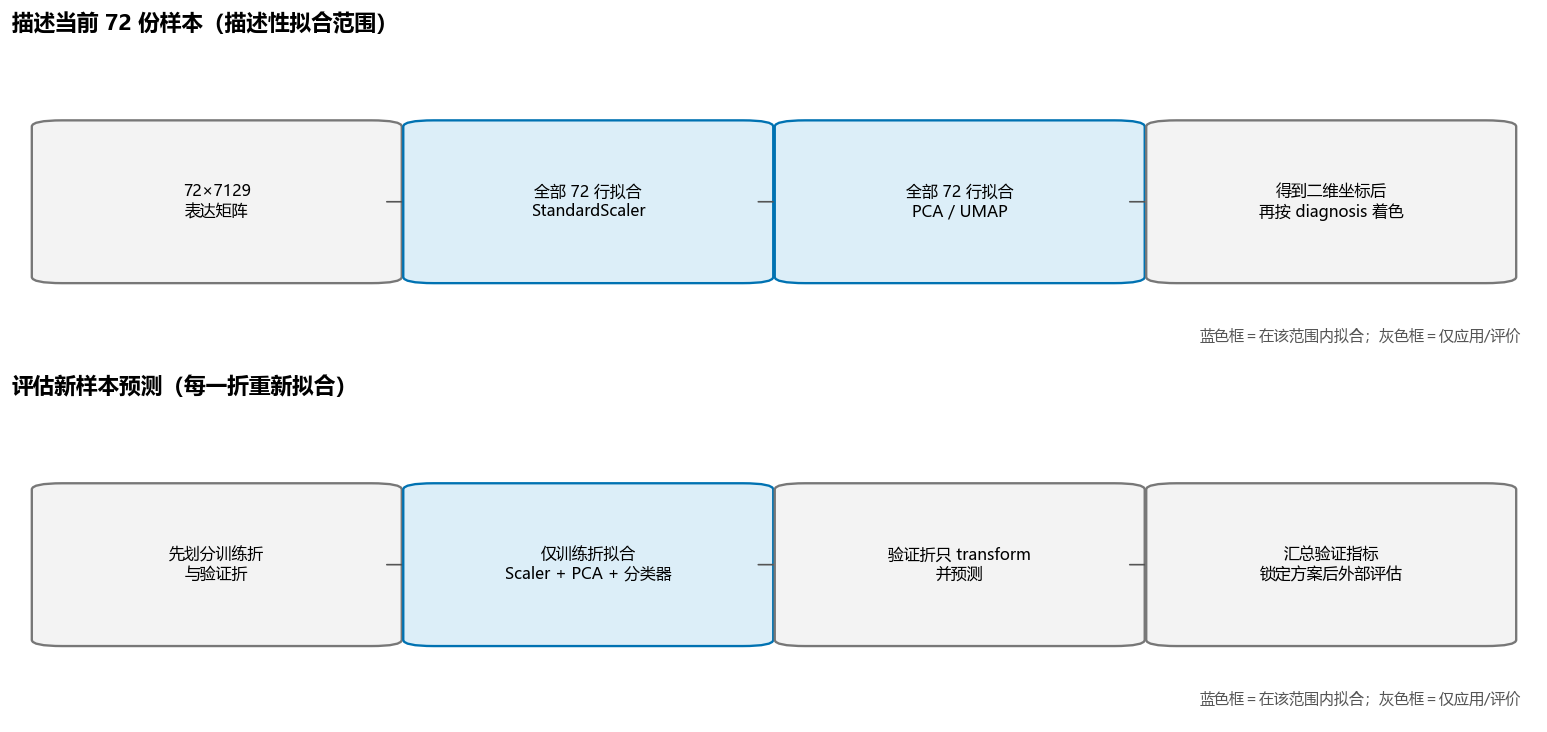

In [3]:
def draw_flow(ax, title, items, fit_indices):
    ax.set_axis_off(); ax.set_title(title, loc="left", fontsize=13, fontweight="bold", pad=10)
    n, margin, gap = len(items), 0.025, 0.025
    width, y0, height = (1 - 2 * margin - (n - 1) * gap) / n, 0.25, 0.50
    for i, text in enumerate(items):
        x0 = margin + i * (width + gap); is_fit = i in fit_indices
        ax.add_patch(FancyBboxPatch((x0, y0), width, height,
            boxstyle="round,pad=0.012,rounding_size=0.02",
            facecolor="#DCEEF8" if is_fit else "#F3F3F3",
            edgecolor="#0072B2" if is_fit else "#777777", linewidth=1.4))
        ax.text(x0 + width / 2, y0 + height / 2, text, ha="center", va="center", fontsize=9.5)
        if i < n - 1:
            ax.add_patch(FancyArrowPatch((x0 + width, y0 + height / 2),
                (x0 + width + gap, y0 + height / 2), arrowstyle="-|>",
                mutation_scale=12, color="#555555", linewidth=1.0))
    ax.text(0.99, 0.04, "蓝色框＝在该范围内拟合；灰色框＝仅应用/评价",
            ha="right", va="bottom", fontsize=9, color="#555555")

fig, axes = plt.subplots(2, 1, figsize=(13, 6.2))
draw_flow(axes[0], "描述当前 72 份样本（描述性拟合范围）",
    ["72×7129\n表达矩阵", "全部 72 行拟合\nStandardScaler",
     "全部 72 行拟合\nPCA / UMAP", "得到二维坐标后\n再按 diagnosis 着色"], {1, 2})
draw_flow(axes[1], "评估新样本预测（每一折重新拟合）",
    ["先划分训练折\n与验证折", "仅训练折拟合\nScaler + PCA + 分类器",
     "验证折只 transform\n并预测", "汇总验证指标\n锁定方案后外部评估"], {1})
plt.tight_layout(); plt.show()

### 信息泄露说明

PCA 虽然不读取标签，但如果先在全数据上标准化和 PCA，验证样本仍参与了均值、标准差、协方差和主成分方向的估计。之后的交叉验证会让训练折使用已经包含验证折分布信息的表示，因此不再模拟真正未见样本。预测流程必须在每一折的训练部分重新拟合标准化、PCA 和分类器。

### 可选验证：只在原始 38 个 train 样本内

固定 `StratifiedKFold(3, shuffle=True, random_state=42)`，比较 `StandardScaler → 1NN` 与 `StandardScaler → PCA(10, full) → 1NN`。不使用另 34 个 test 样本评分或调参。

In [4]:
train_mask = df["original_split"].eq("train").to_numpy()
X_train, y_train = X.loc[train_mask], y.loc[train_mask]
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
splits = list(cv.split(X_train, y_train))
pipe_knn = Pipeline([("scale", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=1))])
pipe_pca_knn = Pipeline([("scale", StandardScaler()),
    ("pca", PCA(n_components=10, svd_solver="full")),
    ("knn", KNeighborsClassifier(n_neighbors=1))])
cv_knn = cross_val_score(pipe_knn, X_train, y_train, cv=splits, scoring="balanced_accuracy")
cv_pca_knn = cross_val_score(pipe_pca_knn, X_train, y_train, cv=splits, scoring="balanced_accuracy")
cv_results = pd.DataFrame({"fold": [1, 2, 3],
    "StandardScaler → 1NN": cv_knn,
    "StandardScaler → PCA(10) → 1NN": cv_pca_knn})
cv_results.loc[len(cv_results)] = ["均值", cv_knn.mean(), cv_pca_knn.mean()]
display(cv_results.style.format({"StandardScaler → 1NN": "{:.6f}",
    "StandardScaler → PCA(10) → 1NN": "{:.6f}"}))
cv_results.to_csv(RESULT_DIR / "optional_cv.csv", index=False, encoding="utf-8-sig")

,fold,StandardScaler → 1NN,StandardScaler → PCA(10) → 1NN
0,1,0.819444,0.694444
1,2,0.875000,0.763889
2,3,0.833333,0.833333
3,均值,0.842593,0.763889


本次固定比较中，PCA(10) 的三折平均 balanced accuracy 为 0.763889，低于未降维的 0.842593；这不证明 PCA 在其他维数、模型或队列中一定无用。

## 任务 2：PCA 保留什么、丢掉什么

### 2.1 按探针标准化

In [5]:
scaler = StandardScaler()
Z = scaler.fit_transform(X)  # 描述性分析：在全部 72 行拟合
standardization_check = pd.Series({
    "列均值绝对值的最大值": np.abs(Z.mean(axis=0)).max(),
    "列总体标准差与 1 的最大绝对偏差（ddof=0）": np.abs(Z.std(axis=0, ddof=0) - 1).max(),
}, name="检查值")
display(standardization_check.to_frame())

,检查值
列均值绝对值的最大值,5.982869e-16
列总体标准差与 1 的最大绝对偏差（ddof=0）,3.330669e-16


两项误差都在 $10^{-16}$ 量级，说明变换符合预期。这里的 z-score 让各探针按自身变异尺度参与 PCA；它不等于微阵列背景校正、芯片间归一化或批次校正。

### 2.2 标准化 PCA、散点图和累计解释率

,结果
PC1 解释率,0.149216
PC2 解释率,0.094462
PC1+PC2,0.243678
达到 50% 的 PC 数,11.000000
达到 80% 的 PC 数,37.000000
达到 90% 的 PC 数,51.000000
达到 95% 的 PC 数,60.000000
中心化矩阵数值秩,71.000000


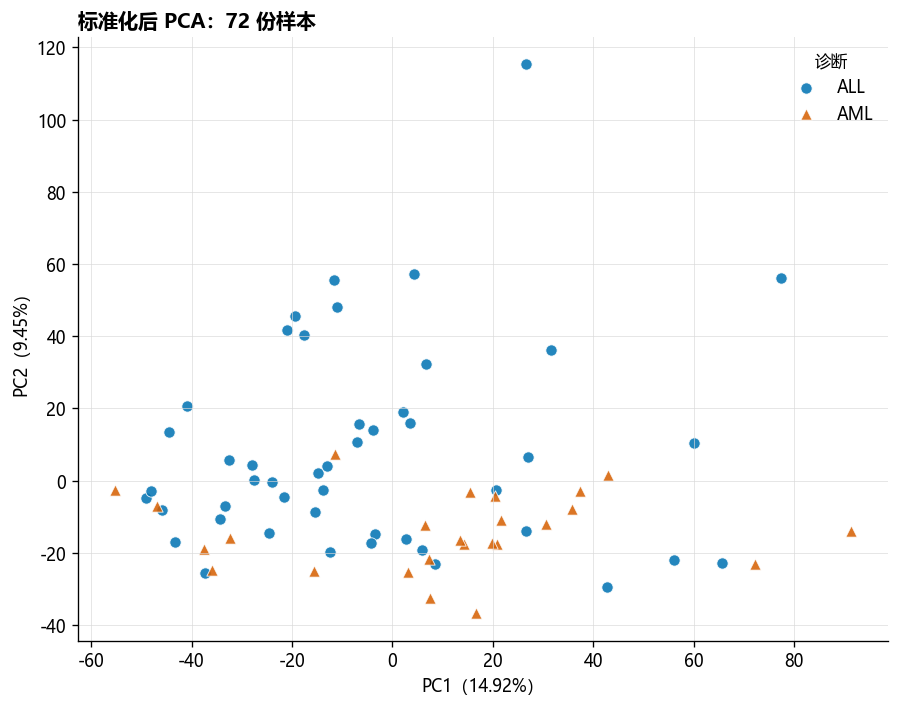

In [6]:
pca_std = PCA(svd_solver="full")
scores_std = pca_std.fit_transform(Z)
evr_std = pca_std.explained_variance_ratio_
cum_std = np.cumsum(evr_std)
def components_for(cumulative, threshold):
    return int(np.searchsorted(cumulative, threshold) + 1)
pca_summary = pd.Series({
    "PC1 解释率": evr_std[0], "PC2 解释率": evr_std[1],
    "PC1+PC2": evr_std[:2].sum(), "达到 50% 的 PC 数": components_for(cum_std, 0.50),
    "达到 80% 的 PC 数": components_for(cum_std, 0.80),
    "达到 90% 的 PC 数": components_for(cum_std, 0.90),
    "达到 95% 的 PC 数": components_for(cum_std, 0.95),
    "中心化矩阵数值秩": np.linalg.matrix_rank(Z),
})
display(pca_summary.to_frame("结果"))

def scatter_by_diagnosis(ax, coords, xlabel, ylabel, title):
    for label in ("ALL", "AML"):
        mask = y.eq(label).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=46, c=COLORS[label],
                   marker=MARKERS[label], label=label, alpha=0.86,
                   edgecolors="white", linewidths=0.55)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.title.set_fontweight("bold"); ax.title.set_ha("left"); ax.title.set_position((0, 1.0))
    ax.grid(True, color="#D9D9D9", linewidth=0.6, alpha=0.65)
    ax.legend(frameon=False, title="诊断")

fig, ax = plt.subplots(figsize=(7.6, 6.0))
scatter_by_diagnosis(ax, scores_std[:, :2],
    f"PC1（{evr_std[0]:.2%}）", f"PC2（{evr_std[1]:.2%}）", "标准化后 PCA：72 份样本")
plt.tight_layout(); plt.show()

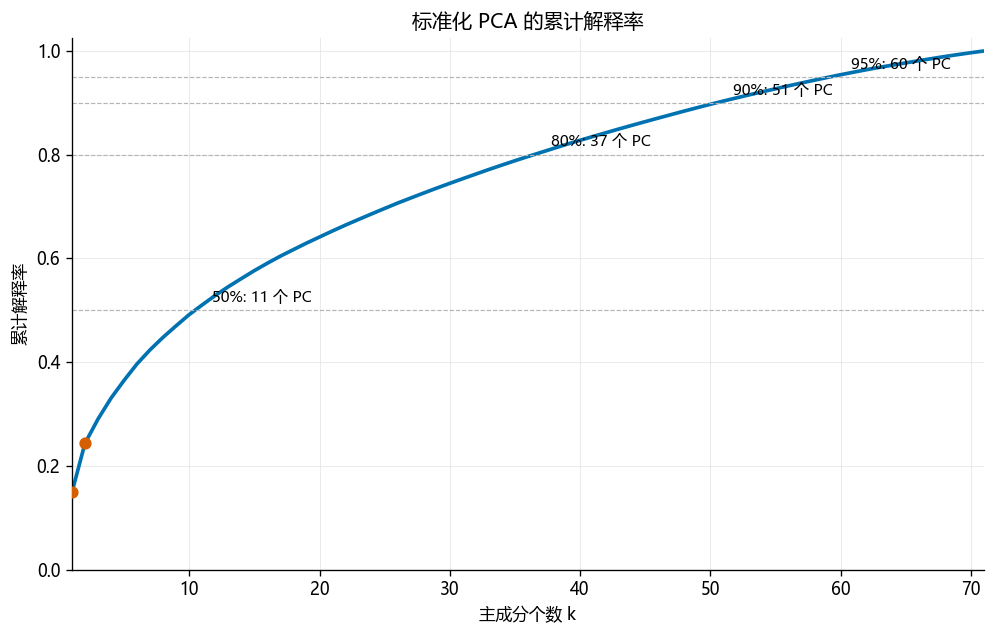

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 5.4))
x_axis = np.arange(1, 72)
ax.plot(x_axis, cum_std[:71], color="#0072B2", linewidth=2.2)
ax.scatter([1, 2], cum_std[:2], color="#D55E00", s=40, zorder=3)
for level in (0.50, 0.80, 0.90, 0.95):
    k = components_for(cum_std, level)
    ax.axhline(level, color="#B5B5B5", linewidth=0.7, linestyle="--")
    ax.annotate(f"{level:.0%}: {k} 个 PC", xy=(k, level), xytext=(6, 5),
                textcoords="offset points", fontsize=9)
ax.set(xlabel="主成分个数 k", ylabel="累计解释率", title="标准化 PCA 的累计解释率")
ax.set(xlim=(1, 71), ylim=(0, 1.025)); ax.grid(True, color="#E2E2E2", linewidth=0.6, alpha=0.7)
plt.tight_layout(); plt.show()

PC1 和 PC2 分别解释 14.9216% 与 9.4462%，合计 24.3678%。二维图压缩并遗漏了约 75.63% 的标准化总方差，不能代表完整表达空间。

### 2.3 PC1 方向权重

本报告按课程约定，把 `components_.T` 称为主成分方向权重（loading）。

In [8]:
weights_std = pd.Series(pca_std.components_[0], index=X.columns, name="PC1_weight")
top_std = weights_std.loc[weights_std.abs().nlargest(5).index].rename_axis("probe").reset_index()
top_std["abs_weight"] = top_std["PC1_weight"].abs()
display(top_std.style.format({"PC1_weight": "{:+.6f}", "abs_weight": "{:.6f}"}))
top_std.to_csv(RESULT_DIR / "pca_standardized_top5.csv", index=False, encoding="utf-8-sig")
manual_pc1 = Z @ pca_std.components_[0]
print("手工加权与 sklearn PC1 得分的最大绝对差：", np.max(np.abs(manual_pc1 - scores_std[:, 0])))

,probe,PC1_weight,abs_weight
0,X92518_s_at,+0.028786,0.028786
1,X95190_at,-0.028177,0.028177
2,X98253_at,+0.027927,0.027927
3,X82895_at,+0.027871,0.027871
4,Y09616_at,+0.027757,0.027757


手工加权与 sklearn PC1 得分的最大绝对差： 1.9895196601282805e-13


例如 `X92518_s_at` 的标准化值每增加 1，在其他标准化探针值不变时，样本 PC1 得分按当前方向约增加 0.028786。完整 PC1 是 7,129 项加权和，不能把它当作某一个探针；高权重也不等于差异表达显著、分类重要或致病。

### 2.4 仅中心化、未标准化的原尺度 PCA

,标准化 PCA,原尺度 PCA
PC1 解释率,0.149216,0.174278
PC2 解释率,0.094462,0.103386
前两项合计,0.243678,0.277664
达到 80% 的 PC 数,37.000000,20.000000


,probe,PC1_weight,abs_weight
0,M25079_s_at,+0.352388,0.352388
1,hum_alu_at,+0.313552,0.313552
2,HG1428-HT1428_s_at,+0.234867,0.234867
3,L06499_at,+0.210453,0.210453
4,J04617_s_at,+0.196253,0.196253


两种 PC1 前五探针重叠数： 0


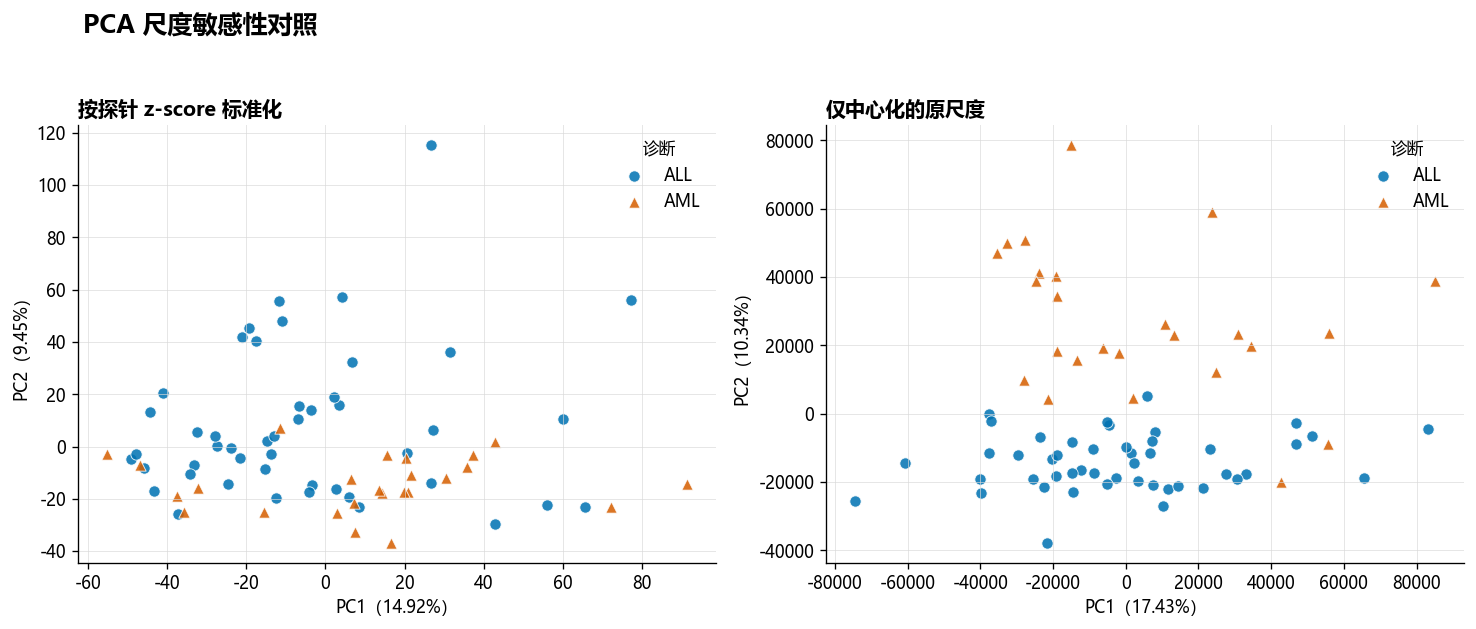

In [9]:
pca_raw = PCA(svd_solver="full")  # sklearn PCA 默认中心化，不除标准差
scores_raw = pca_raw.fit_transform(X)
evr_raw = pca_raw.explained_variance_ratio_; cum_raw = np.cumsum(evr_raw)
weights_raw = pd.Series(pca_raw.components_[0], index=X.columns, name="PC1_weight")
top_raw = weights_raw.loc[weights_raw.abs().nlargest(5).index].rename_axis("probe").reset_index()
top_raw["abs_weight"] = top_raw["PC1_weight"].abs()
scale_comparison = pd.DataFrame({
    "标准化 PCA": [evr_std[0], evr_std[1], evr_std[:2].sum(), components_for(cum_std, 0.80)],
    "原尺度 PCA": [evr_raw[0], evr_raw[1], evr_raw[:2].sum(), components_for(cum_raw, 0.80)],
}, index=["PC1 解释率", "PC2 解释率", "前两项合计", "达到 80% 的 PC 数"])
display(scale_comparison)
display(top_raw.style.format({"PC1_weight": "{:+.6f}", "abs_weight": "{:.6f}"}))
print("两种 PC1 前五探针重叠数：", len(set(top_std["probe"]) & set(top_raw["probe"])))
top_raw.to_csv(RESULT_DIR / "pca_raw_top5.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.3))
scatter_by_diagnosis(axes[0], scores_std[:, :2],
    f"PC1（{evr_std[0]:.2%}）", f"PC2（{evr_std[1]:.2%}）", "按探针 z-score 标准化")
scatter_by_diagnosis(axes[1], scores_raw[:, :2],
    f"PC1（{evr_raw[0]:.2%}）", f"PC2（{evr_raw[1]:.2%}）", "仅中心化的原尺度")
fig.suptitle("PCA 尺度敏感性对照", fontsize=15, fontweight="bold", x=0.06, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

原尺度 PC1/PC2 合计解释 27.7664%，前五权重与标准化结果无重叠，说明大尺度/大方差探针显著改变方向。标准化让每列方差约为 1，但可能放大低变异噪声；两种分析的总方差分母不同，不能只比较谁的解释率高就判断谁“生物信息更多”。

**概念小结：**

- PC1 在单位长度约束下最大化当前输入的投影方差，不等于最能区分 ALL/AML 的方向，也不是一个基因。
- 同时翻转某主成分全部权重和样本得分，只会翻转轴朝向，不改变解释率、距离或结论。
- 中心化后 72 个样本存在一项和为零的线性约束，秩至多为 71；本次数值秩为 71。
- 本次 PC1 可解释为：全部标准化探针的线性组合，解释 14.9216% 的标准化总方差，其中 `X92518_s_at` 的方向系数为 +0.028786。
- 不能据此推出：该探针致病、显著差异表达，或 PC1–PC2 可以预测新患者。

## 任务 3：UMAP 稳定性

四个条件只改变一个规定因素，保持二维输出、欧氏距离、标准化矩阵和全部 7,129 个探针不变。

In [10]:
umap_specs = {
    "baseline": dict(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=42, n_jobs=1),
    "neighbors5": dict(n_neighbors=5, min_dist=0.1, metric="euclidean", random_state=42, n_jobs=1),
    "min_dist05": dict(n_neighbors=15, min_dist=0.5, metric="euclidean", random_state=42, n_jobs=1),
    "seed7": dict(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=7, n_jobs=1),
}
embeddings = {name: UMAP(n_components=2, **params).fit_transform(Z)
              for name, params in umap_specs.items()}
display(pd.DataFrame(umap_specs).T)

,n_neighbors,min_dist,metric,random_state,n_jobs
baseline,15,0.1,euclidean,42,1
neighbors5,5,0.1,euclidean,42,1
min_dist05,15,0.5,euclidean,42,1
seed7,15,0.1,euclidean,7,1


### 3.1 PCA 与 UMAP 并排比较

PCA 是可追踪 loading 和 explained variance 的线性投影；UMAP 是侧重局部邻域的非线性嵌入，UMAP1/2 没有固定的基因、疾病单位或与 PCA 等价的解释率。

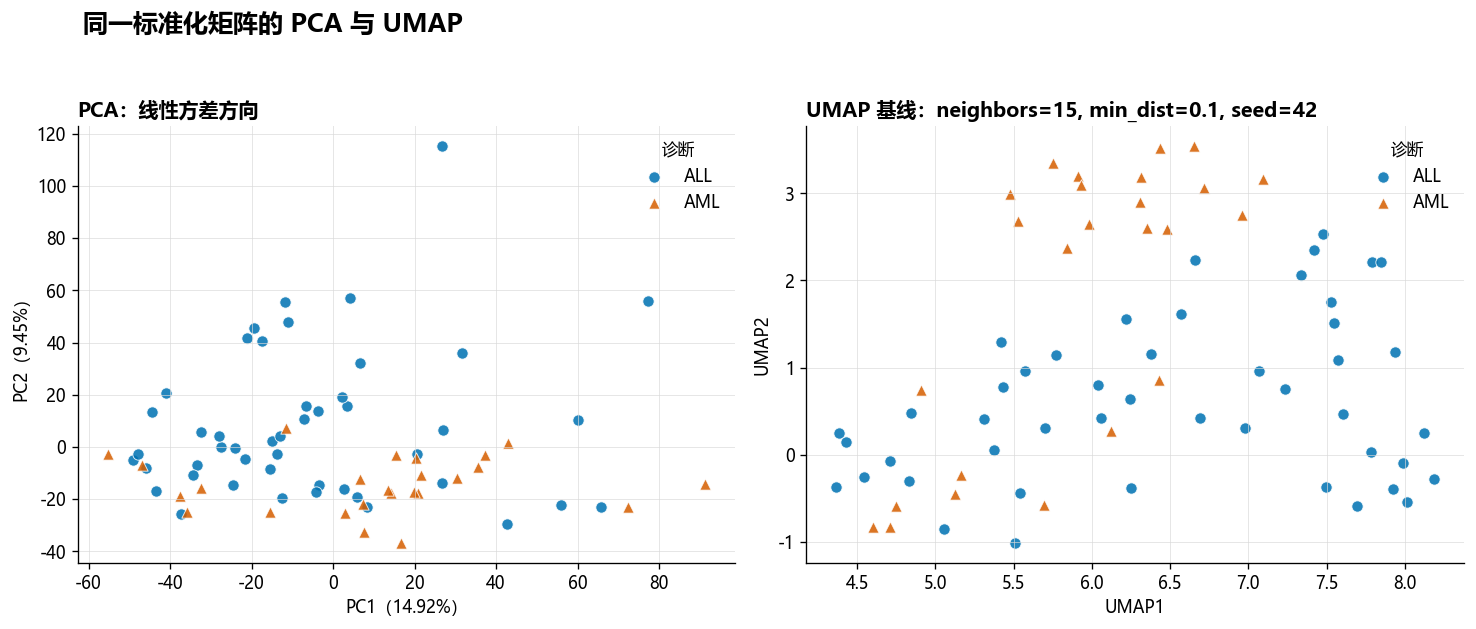

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 5.3))
scatter_by_diagnosis(axes[0], scores_std[:, :2],
    f"PC1（{evr_std[0]:.2%}）", f"PC2（{evr_std[1]:.2%}）", "PCA：线性方差方向")
scatter_by_diagnosis(axes[1], embeddings["baseline"],
    "UMAP1", "UMAP2", "UMAP 基线：neighbors=15, min_dist=0.1, seed=42")
fig.suptitle("同一标准化矩阵的 PCA 与 UMAP", fontsize=15, fontweight="bold", x=0.06, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.94)); plt.show()

### 3.2 四组 UMAP 全部保留

不能只挑分组最清楚的一张图。下图保留基线、邻居数、`min_dist` 与随机种子对照。

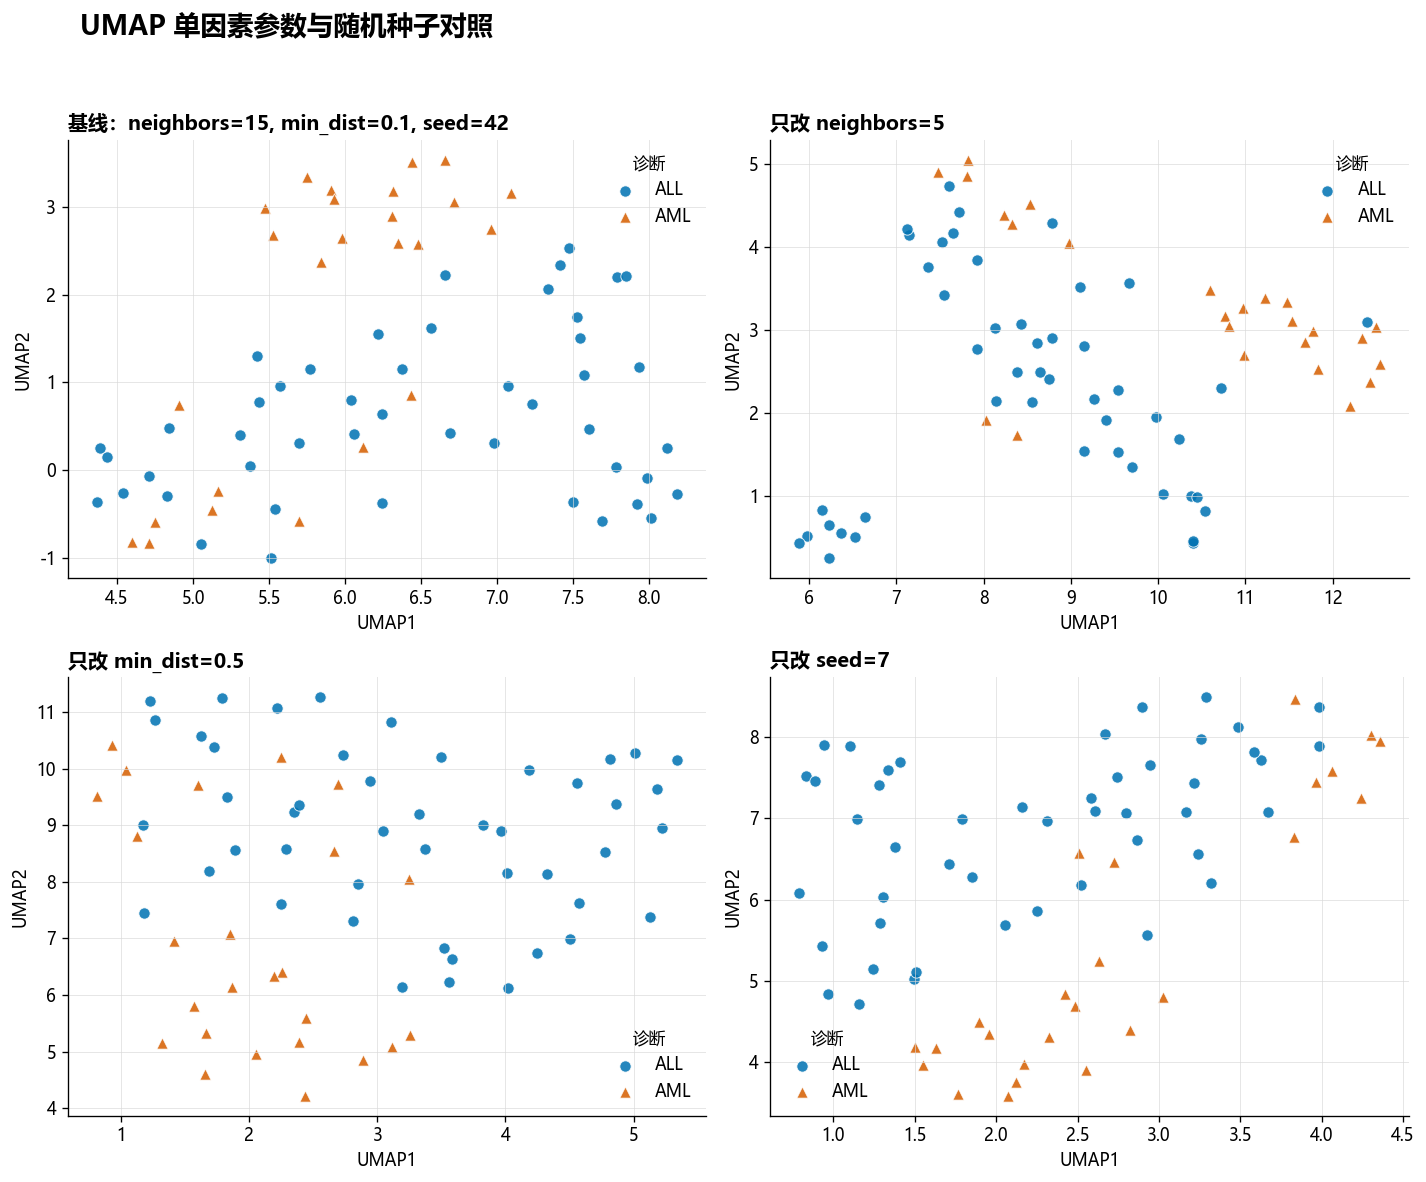

In [12]:
titles = {
    "baseline": "基线：neighbors=15, min_dist=0.1, seed=42",
    "neighbors5": "只改 neighbors=5", "min_dist05": "只改 min_dist=0.5",
    "seed7": "只改 seed=7",
}
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, name in zip(axes.ravel(), ("baseline", "neighbors5", "min_dist05", "seed7")):
    scatter_by_diagnosis(ax, embeddings[name], "UMAP1", "UMAP2", titles[name])
fig.suptitle("UMAP 单因素参数与随机种子对照", fontsize=16, fontweight="bold", x=0.06, ha="left")
plt.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

### 3.3 用样本编号量化局部稳定性

为避免只凭岛屿外观判断，下面按 `sample_id` 对齐，比较每个样本在二维中的 5 近邻集合。Jaccard、trustworthiness 和 Procrustes 只是辅助稳定性指标，不是临床性能。

In [13]:
def neighbor_sets(values, k=5):
    distances = pairwise_distances(values, metric="euclidean")
    order = np.argsort(distances, axis=1)[:, 1:k + 1]
    return [set(map(int, row)) for row in order]

def jaccard_summary(left, right):
    values = np.array([len(a & b) / len(a | b) for a, b in zip(left, right)])
    return values.mean(), np.median(values), values.min(), values.max()

high_dim_neighbors = neighbor_sets(Z, k=5)
embedding_neighbors = {name: neighbor_sets(emb, k=5) for name, emb in embeddings.items()}
baseline_neighbors = embedding_neighbors["baseline"]
stability_rows = []
for name, emb in embeddings.items():
    b_mean, b_median, b_min, b_max = jaccard_summary(baseline_neighbors, embedding_neighbors[name])
    h_mean, _, _, _ = jaccard_summary(high_dim_neighbors, embedding_neighbors[name])
    disparity = 0.0 if name == "baseline" else procrustes(embeddings["baseline"], emb)[2]
    stability_rows.append({
        "setting": name, "mean_5NN_Jaccard_vs_baseline": b_mean,
        "median_5NN_Jaccard_vs_baseline": b_median,
        "min_vs_baseline": b_min, "max_vs_baseline": b_max,
        "mean_5NN_Jaccard_vs_high_dim": h_mean,
        "trustworthiness_k5": trustworthiness(Z, emb, n_neighbors=5, metric="euclidean"),
        "Procrustes_disparity_vs_baseline": disparity,
    })
stability = pd.DataFrame(stability_rows)
display(stability.style.format({col: "{:.4f}" for col in stability.columns if col != "setting"}))
stability.to_csv(RESULT_DIR / "umap_stability.csv", index=False, encoding="utf-8-sig")

common_counts, robust_pairs = [], []
for i in range(len(df)):
    common_counts.append(len(set.intersection(*(embedding_neighbors[name][i] for name in embeddings))))
    for j in range(i + 1, len(df)):
        if all(j in sets[i] and i in sets[j] for sets in embedding_neighbors.values()):
            robust_pairs.append({"sample_a": df.loc[i, "sample_id"],
                "diagnosis_a": df.loc[i, "diagnosis"], "sample_b": df.loc[j, "sample_id"],
                "diagnosis_b": df.loc[j, "diagnosis"]})
robust_pairs_df = pd.DataFrame(robust_pairs)
print(f"四种嵌入中共同 5 近邻数：均值={np.mean(common_counts):.3f}，中位数={np.median(common_counts):.1f}，范围={min(common_counts)}–{max(common_counts)}")
print(f"至少保留 1 个共同近邻的样本：{sum(v >= 1 for v in common_counts)}/72")
print(f"四种设置均互为 5 近邻的样本对：{len(robust_pairs_df)} 对")
display(robust_pairs_df.head(15))
robust_pairs_df.to_csv(RESULT_DIR / "robust_mutual_5nn_pairs.csv", index=False, encoding="utf-8-sig")

,setting,mean_5NN_Jaccard_vs_baseline,median_5NN_Jaccard_vs_baseline,min_vs_baseline,max_vs_baseline,mean_5NN_Jaccard_vs_high_dim,trustworthiness_k5,Procrustes_disparity_vs_baseline
0,baseline,1.0000,1.0000,1.0000,1.0000,0.2896,0.8036,0.0000
1,neighbors5,0.4311,0.4286,0.0000,1.0000,0.3226,0.8202,0.1740
2,min_dist05,0.5182,0.4286,0.1111,1.0000,0.2773,0.7974,0.1675
3,seed7,0.4716,0.4286,0.0000,1.0000,0.2803,0.8023,0.1617


四种嵌入中共同 5 近邻数：均值=1.944，中位数=2.0，范围=0–5
至少保留 1 个共同近邻的样本：63/72
四种设置均互为 5 近邻的样本对：53 对


,sample_a,diagnosis_a,sample_b,diagnosis_b
0,G001,ALL,G003,ALL
1,G001,ALL,G004,ALL
2,G001,ALL,G008,ALL
3,G002,ALL,G011,ALL
4,G003,ALL,G009,ALL
5,G004,ALL,G007,ALL
6,G004,ALL,G008,ALL
7,G004,ALL,G049,ALL
8,G005,ALL,G015,ALL
9,G006,ALL,G023,ALL


四种设置中，每个样本平均保留 1.944/5 个共同邻居，63/72 个样本至少保留一个共同邻居，说明部分局部关系可复现；但相对基线的平均 5-NN Jaccard 只有 0.4311–0.5182，说明邻域并不完全稳定。`min_dist=0.5` 让点更分散，`neighbors=5` 更强调小尺度关系，仅更换种子也改变坐标和局部布局。

岛屿数量、岛屿间距离、方向、面积和密度会随设置变化，也可能经旋转、翻转或平移而改变，因此不能直接量化生物差异。UMAP 常用于单细胞或复杂表型，是因为它便于展示高维数据中的候选非线性局部结构；图形只能帮助提出假设。

### 3.4 全部样本与坐标对应表

下表保留 PCA 与四种 UMAP 坐标的 72 行对应关系，并写入临时结果目录。

In [14]:
coordinates = df[meta_cols].copy()
coordinates["PC1"] = scores_std[:, 0]; coordinates["PC2"] = scores_std[:, 1]
for name, emb in embeddings.items():
    coordinates[f"{name}_UMAP1"] = emb[:, 0]
    coordinates[f"{name}_UMAP2"] = emb[:, 1]
coordinates.to_csv(RESULT_DIR / "coordinates.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_rows", 100, "display.max_columns", None):
    display(coordinates.round(4))

,sample_id,original_split,diagnosis,PC1,PC2,baseline_UMAP1,baseline_UMAP2,neighbors5_UMAP1,neighbors5_UMAP2,min_dist05_UMAP1,min_dist05_UMAP2,seed7_UMAP1,seed7_UMAP2
0,G001,train,ALL,27.1052,6.4485,7.5276,1.7493,10.0554,1.0224,4.2428,6.7327,0.9288,5.4303
1,G002,train,ALL,3.5074,15.8458,7.2335,0.7535,9.5368,2.2734,4.3212,8.1438,1.7124,6.4438
2,G003,train,ALL,60.0064,10.3923,7.5447,1.5127,9.7014,1.3470,4.5012,6.9848,1.2856,5.7070
3,G004,train,ALL,20.6404,-2.6234,7.3380,2.0634,10.3797,0.9967,4.0197,6.1236,1.2415,5.1415
4,G005,train,ALL,-21.0120,41.7942,7.7868,0.0330,6.5187,0.5033,4.8637,9.3811,1.4099,7.7008
5,G006,train,ALL,-3.4597,-14.7572,6.5694,1.6204,10.2391,1.6793,2.8077,7.3104,2.0525,5.6845
6,G007,train,ALL,26.6185,-13.9258,7.4755,2.5315,10.5337,0.8202,3.1955,6.1335,1.1589,4.7115
7,G008,train,ALL,56.0706,-22.1430,7.4176,2.3450,10.4496,0.9876,3.5556,6.2232,0.9641,4.8349
8,G009,train,ALL,31.6280,36.0868,7.5762,1.0909,9.5396,1.5315,4.5714,7.6283,1.3022,6.0325
9,G010,train,ALL,-13.7260,-2.7296,6.3781,1.1599,9.2694,2.1645,2.8483,7.9661,2.5191,6.1823


### 3.5 三条证据边界判断

1. 图能支持在给定标准化、度量、参数和种子下提出候选邻域；UMAP1/2、岛屿间距、方向和面积没有固定生物学单位。
2. 参数对照显示部分邻近关系稳定，但平均 5-NN Jaccard 只有 0.4311–0.5182；岛屿数量不能证明真实亚型数量或疾病机制。
3. 标签着色显示当前记录存在 ALL/AML 视觉趋势且并非完全分离；它不能估计新患者性能，也不能在缺少批次字段时宣称排除了批次影响。

## 任务 4：主张—证据—推理—边界

**主张：**我不同意“二维图分得开就证明发现了疾病机制，并可以预测新患者”，因为本次 PCA/UMAP 只描述当前 72 份记录在特定分析设置下的低维结构。  
**证据：**标准化 PCA 的 PC1、PC2 只解释 14.9216% 和 9.4462%，PC1 最大绝对权重是 `X92518_s_at` 的 +0.028786；UMAP 仅把 `n_neighbors` 从 15 改为 5，二维 5 近邻集合相对基线的平均 Jaccard 就只有 0.4311。  
**推理：**PCA 优化总体投影方差、UMAP 近似局部邻域，而非疾病因果或未见样本预测，所以视觉分离最多提出候选结构，不能把高 loading 探针称为致病基因，也不能把岛屿称为确证亚型。  
**边界：**数据缺少患者重复、中心和批次字段；要升级为生物医学结论，应在预注册的独立多中心患者队列锁定流程做外部验证，并用跨平台表达复现与功能干预验证稳定候选通路。

## 课后作业三问

### 1. PCA 第一主成分代表什么？

PC1 是在本次标准化 7,129 个探针空间中，使 72 个样本投影方差最大的单位方向，是全部探针的线性组合。本次它解释 14.9216% 的标准化总方差；`X92518_s_at` 的方向权重为 +0.028786，表示它对当前方向的加权贡献，但其绝对值大不等于差异表达显著、分类最重要或具有致病作用。

### 2. 为什么 PCA 前通常需要考虑标准化？

PCA 按方差找方向，仅中心化时大尺度或大方差探针更容易主导。原尺度 PCA 的前两项解释 27.7664%，前五权重与标准化结果零重叠；标准化后各探针方差约为 1，前两项解释 24.3678%，方向明显改变。标准化有利于比较不同变异尺度的探针，但也可能放大低变异噪声，而且不替代微阵列上游归一化或批次校正。

### 3. UMAP 图能说明什么，不能说明什么？

UMAP 可展示固定分析条件下的候选局部邻域；四种设置仍有 63/72 个样本至少保留一个共同 5 近邻，说明部分局部关系可复现。但只把种子改为 7，相对基线的平均二维 5-NN Jaccard 为 0.4716，布局、方向和类别混合位置均改变。因此岛屿数量、簇间距离、面积和方向不能直接解释为机制、真实亚型或效应大小；当前标签着色也不能估计新患者表现或排除批次影响。

## 运行与 AI 使用记录

- 随机种子：UMAP 基线及参数对照为 42，随机种子对照为 7；训练内分层三折为 42。
- 输入：全部 7,129 个探针，未按 diagnosis 筛选；排除三个元数据列。
- 标准化：`StandardScaler` 按探针 z-score，`ddof=0`；原尺度对照只中心化。
- AI 使用：AI 协助梳理材料、搭建代码和组织报告。所有结论逐项对照课程 README、工作单、数据说明、讲义和课件，并在指定版本环境中从课堂 CSV 重新计算；保留代码、实际输出、参数、图与坐标表，不把图形外观或 AI 推测写成生物医学事实。